# K-Nearest Neighbors (KNN) — From Intuition to Cross-Validation

**Dataset:** Built-in scikit-learn Iris dataset (no external download)  
**Problem:** Predict iris flower species using **two features**: petal length and petal width  
**Model:** `KNeighborsClassifier` + `StandardScaler` + `GridSearchCV`  
**Audience:** Guided classroom practical; code cells can be run from top to bottom.

### Learning outcomes
1. Calculate Euclidean distance manually for two features and apply majority voting.
2. Inspect and visualize a standard three-class classification dataset.
3. Explain why KNN needs feature scaling and why the scaler belongs inside a pipeline.
4. Split into train/test data and tune hyperparameters using **5-fold stratified CV on training data only**.
5. Explain `best_params_`, `best_score_`, `cv_results_`, test accuracy, confusion matrix and classification report.
6. Predict a new sample and inspect its neighbors.

> **Important:** We reserve the test set until after model selection. All preprocessing in CV is fitted *inside* each fold.

## A. Start with a two-feature manual KNN example

Before using scikit-learn, let's classify a student using **study hours (X₁)** and **mock score (X₂)**. We will use Euclidean distance on the original feature values to illustrate the arithmetic. In production, differences in scale would need attention.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.2})

students = pd.DataFrame({
    "student": list("ABCDEFGH"),
    "hours": [1, 2, 3, 4, 5, 6, 7, 4],
    "mock_score": [20, 30, 50, 60, 70, 80, 85, 45],
    "result": ["Fail", "Fail", "Fail", "Pass", "Pass", "Pass", "Pass", "Fail"],
})
new_student = np.array([4.6, 66.0])
display(students)
print("New student: hours =", new_student[0], ", score =", new_student[1])

,student,hours,mock_score,result
0,A,1,20,Fail
1,B,2,30,Fail
2,C,3,50,Fail
3,D,4,60,Pass
4,E,5,70,Pass
5,F,6,80,Pass
6,G,7,85,Pass
7,H,4,45,Fail


New student: hours = 4.6 , score = 66.0


In [2]:
# Distance from the new student to each training record:
# sqrt((hours - 4.6)^2 + (mock_score - 66)^2)
coordinates = students[["hours", "mock_score"]].to_numpy()
students["euclidean_distance"] = np.sqrt(((coordinates - new_student) ** 2).sum(axis=1))
ranked_students = students.sort_values("euclidean_distance").reset_index(drop=True)
display(ranked_students.round(2))

k_manual = 3
nearest_students = ranked_students.head(k_manual)
prediction_manual = nearest_students["result"].mode().iloc[0]
print(f"K = {k_manual}; nearest = {nearest_students['student'].tolist()}")
print("Vote counts:", nearest_students["result"].value_counts().to_dict())
print("Manual KNN prediction:", prediction_manual)

,student,hours,mock_score,result,euclidean_distance
0,E,5,70,Pass,4.02
1,D,4,60,Pass,6.03
2,F,6,80,Pass,14.07
3,C,3,50,Fail,16.08
4,G,7,85,Pass,19.15
5,H,4,45,Fail,21.01
6,B,2,30,Fail,36.09
7,A,1,20,Fail,46.14


K = 3; nearest = ['E', 'D', 'F']
Vote counts: {'Pass': 3}
Manual KNN prediction: Pass


The Euclidean distance between the new student **(4.6, 66)** and student E **(5, 70)** is:

\[
 d=\sqrt{(4.6-5)^2 + (66-70)^2}=\sqrt{16.16}\approx 4.02.
\]

**Check your understanding:** If we choose `K=5`, which five students vote? Does the final predicted class change?

**Scaling note:** The score feature has a much wider range than study hours, so raw Euclidean distances overweight mock scores. This example is for arithmetic only.

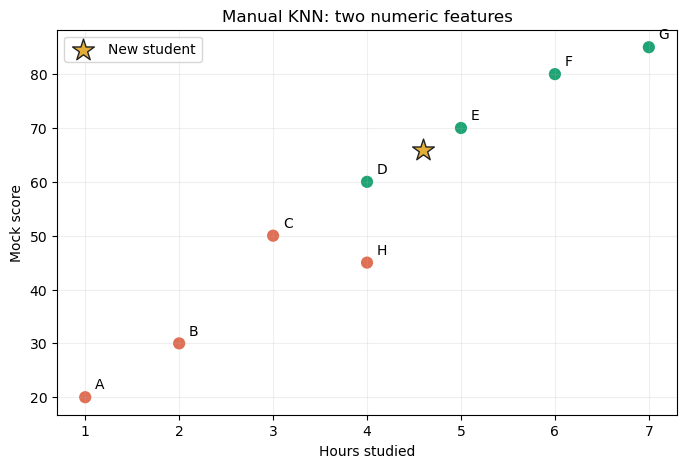

In [3]:
fig, ax = plt.subplots()
colors = students["result"].map({"Pass": "#20a475", "Fail": "#df7056"})
ax.scatter(students["hours"], students["mock_score"], c=colors, s=100, edgecolor="white", linewidth=1.2)
for row in students.itertuples():
    ax.annotate(row.student, (row.hours, row.mock_score), xytext=(7, 6), textcoords="offset points")
ax.scatter(*new_student, marker="*", c="#e2ad38", edgecolor="#222222", s=270, label="New student", zorder=5)
ax.set(xlabel="Hours studied", ylabel="Mock score", title="Manual KNN: two numeric features")
ax.legend()
plt.show()

## B. Load the built-in Iris dataset

Iris contains **150 flowers**, **3 species**, and **4 numeric measurements**. To make KNN easy to plot and interpret, we will select only **petal length** and **petal width**. The target remains a **three-class** classification problem.

In [4]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
print("All available features:", iris.feature_names)
print("Target classes:", list(iris.target_names))

feature_names = ["petal length (cm)", "petal width (cm)"]
X = iris.frame[feature_names].copy()
y = iris.target.copy()

print("Feature shape:", X.shape)
print("Class counts:", y.value_counts().sort_index().to_dict())
display(X.head())

All available features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa', 'versicolor', 'virginica']
Feature shape: (150, 2)
Class counts: {0: 50, 1: 50, 2: 50}


,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


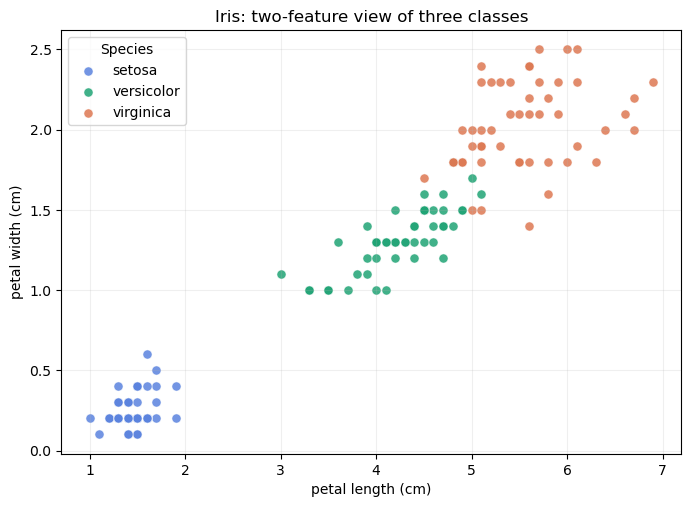

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5))
palette = ["#5b83de", "#20a475", "#dd7852"]
for class_id, name in enumerate(iris.target_names):
    subset = X[y == class_id]
    ax.scatter(subset.iloc[:, 0], subset.iloc[:, 1], label=name,
               color=palette[class_id], alpha=0.85, s=43, edgecolor="white", linewidth=0.4)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title="Iris: two-feature view of three classes")
ax.legend(title="Species")
plt.show()

## C. Make a stratified train/test split

We use **75% for training** and **25% for a final, unseen test**. `stratify=y` preserves class proportions. CV tuning will use the training set only.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts: ", y_test.value_counts().sort_index().to_dict())

Train: 112 rows | Test: 38 rows
Train class counts: {0: 38, 1: 37, 2: 37}
Test class counts:  {0: 12, 1: 13, 2: 13}


## D. Scaling and the KNN pipeline

With two features, Euclidean distance is:

\[
 d(\mathbf{x},\mathbf{z})=\sqrt{(x_1-z_1)^2+(x_2-z_2)^2}
\]

`StandardScaler` transforms each feature using training-data statistics:

\[
 z=\frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}.
\]

A **pipeline** ensures the scaler is fitted only on the training partition of each CV fold. Fitting the scaler on all data **before cross-validation** would cause information leakage.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
print(knn_pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


## E. Five-fold stratified cross-validation: baseline

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` preserves approximate class balance in each fold. Each fold in turn is used for validation, while the other four folds are used for fitting the entire pipeline.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_cv = cross_validate(
    knn_pipeline,
    X_train, y_train,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
)
print("Baseline validation accuracy per fold:", np.round(baseline_cv["test_score"], 3))
print(f"Mean validation accuracy: {baseline_cv['test_score'].mean():.3f}")
print(f"Std across folds:        {baseline_cv['test_score'].std():.3f}")
print(f"Mean train accuracy:     {baseline_cv['train_score'].mean():.3f}")

Baseline validation accuracy per fold: [1.    0.913 1.    0.955 1.   ]
Mean validation accuracy: 0.974
Std across folds:        0.035
Mean train accuracy:     0.971


## F. Hyperparameter tuning with `GridSearchCV`

Search these parameters:

| Parameter | Values | What it controls |
|---|---|---|
| `knn__n_neighbors` | 1, 3, ..., 21 | Number of nearby training examples |
| `knn__weights` | `uniform`, `distance` | Equal votes or higher influence for closer examples |
| `knn__p` | 1, 2 | Manhattan (`p=1`) or Euclidean (`p=2`) distance with Minkowski metric |

**11 × 2 × 2 = 44** combinations; with **5 folds**, the search performs **220 CV fits**, plus a final refit of the winning pipeline on all training rows.

`scoring="accuracy"` is appropriate for this balanced teaching dataset. For imbalanced problems, consider metrics like `f1_macro` or recall as appropriate.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": list(range(1, 22, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    return_train_score=True,
    refit=True, #----> cv hone ke baad pure training data pe fir se run karo
    n_jobs=1,
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best mean CV accuracy: {grid.best_score_:.3f}")
print("Best estimator:", grid.best_estimator_)

Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
Best mean CV accuracy: 0.974
Best estimator: Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(p=1))])


In [10]:
results = pd.DataFrame(grid.cv_results_)
summary_cols = [
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]
best_rows = results.sort_values(["rank_test_score", "std_test_score"]).head(12)
display(best_rows[summary_cols].round(4).reset_index(drop=True))

,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,5,uniform,1,0.9710,0.9735,0.0350,1
1,5,uniform,2,0.9710,0.9735,0.0350,1
2,7,uniform,2,0.9710,0.9735,0.0350,1
3,9,uniform,2,0.9710,0.9735,0.0350,1
4,11,uniform,2,0.9710,0.9735,0.0350,1
5,13,uniform,2,0.9732,0.9735,0.0350,1
6,15,uniform,2,0.9710,0.9735,0.0350,1
7,21,uniform,2,0.9710,0.9735,0.0350,1
8,7,uniform,1,0.9688,0.9648,0.0508,9
9,9,uniform,1,0.9643,0.9648,0.0508,9


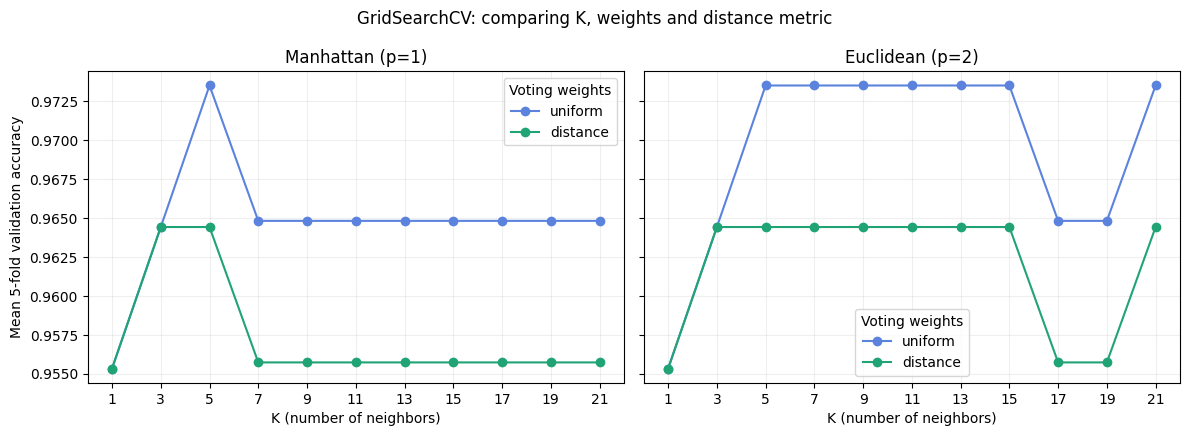

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for axis, p, metric_label in zip(axes, [1, 2], ["Manhattan (p=1)", "Euclidean (p=2)"]):
    for weights, color in [("uniform", "#5b83de"), ("distance", "#20a475")]:
        subset = results[(results["param_knn__p"] == p) & (results["param_knn__weights"] == weights)]
        axis.plot(subset["param_knn__n_neighbors"].astype(int), subset["mean_test_score"],
                  marker="o", color=color, label=weights)
    axis.set(title=metric_label, xlabel="K (number of neighbors)", xticks=list(range(1, 22, 2)))
    axis.legend(title="Voting weights")
axes[0].set_ylabel("Mean 5-fold validation accuracy")
fig.suptitle("GridSearchCV: comparing K, weights and distance metric")
fig.tight_layout()
plt.show()

## G. Final evaluation on the held-out test set

Only **after** choosing the model via CV do we evaluate once on `X_test`. The best pipeline has already been refitted on the whole training set because `refit=True`.

Final training accuracy: 0.973
Best mean CV accuracy:   0.974
Held-out test accuracy:  0.947

Classification report (held-out test set):
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        12
  versicolor      0.923     0.923     0.923        13
   virginica      0.923     0.923     0.923        13

    accuracy                          0.947        38
   macro avg      0.949     0.949     0.949        38
weighted avg      0.947     0.947     0.947        38



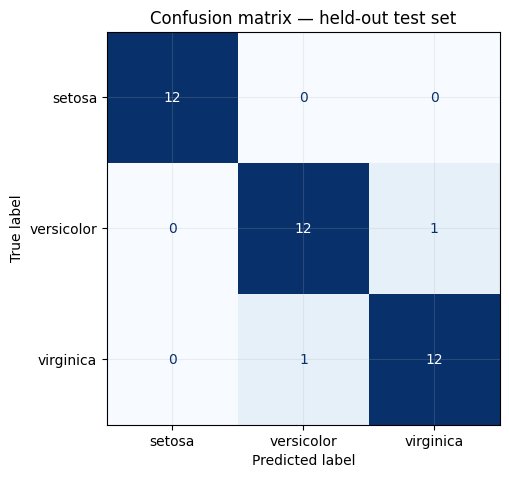

In [12]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
train_accuracy = accuracy_score(y_train, best_model.predict(X_train))
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Final training accuracy: {train_accuracy:.3f}")
print(f"Best mean CV accuracy:   {grid.best_score_:.3f}")
print(f"Held-out test accuracy:  {test_accuracy:.3f}")
print("\nClassification report (held-out test set):")
print(classification_report(y_test, y_pred, target_names=iris.target_names, digits=3))

fig, ax = plt.subplots(figsize=(6.2, 5.1))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Confusion matrix — held-out test set")
plt.show()

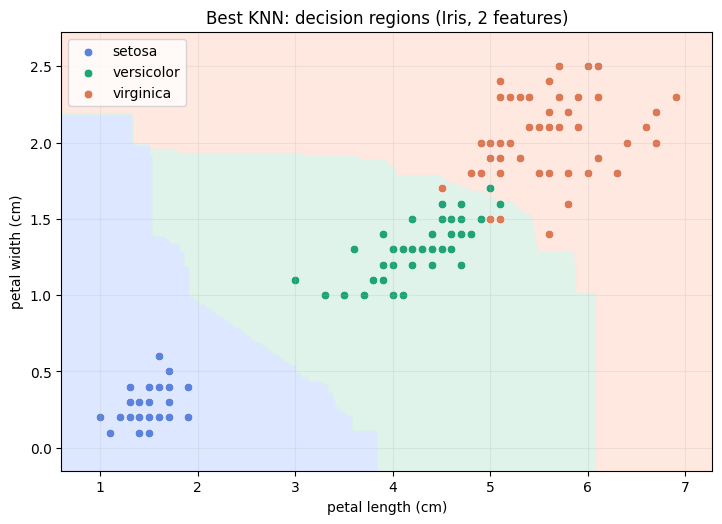

In [13]:
from matplotlib.colors import ListedColormap

step = 0.025
x_min, x_max = X[feature_names[0]].min() - 0.4, X[feature_names[0]].max() + 0.4
y_min, y_max = X[feature_names[1]].min() - 0.25, X[feature_names[1]].max() + 0.25
xx, yy = np.meshgrid(np.arange(x_min, x_max, step), np.arange(y_min, y_max, step))
mesh = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)
region = best_model.predict(mesh).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8.4, 5.7))
ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5, 2.5],
            cmap=ListedColormap(["#dae5ff", "#dcf2e8", "#ffe6dd"]), alpha=0.9)
for cid, species in enumerate(iris.target_names):
    subset = X[y == cid]
    ax.scatter(subset.iloc[:, 0], subset.iloc[:, 1],
               color=["#5b83de", "#20a475", "#dd7852"][cid],
               s=38, label=species, edgecolor="white", linewidth=0.4)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title="Best KNN: decision regions (Iris, 2 features)")
ax.legend()
plt.show()

In [14]:
new_flower = pd.DataFrame([[4.6, 1.4]], columns=feature_names)
predicted_id = int(best_model.predict(new_flower)[0])
probabilities = best_model.predict_proba(new_flower)[0]
print("Predicted species:", iris.target_names[predicted_id])
print("KNN estimated class probabilities:",
      dict(zip(iris.target_names, np.round(probabilities, 3))))

# Access the scaler and KNN inside the fitted pipeline.
scaled_new_flower = best_model.named_steps["scaler"].transform(new_flower)
neighbors_dist, neighbor_idx = best_model.named_steps["knn"].kneighbors(scaled_new_flower)
neighbor_table = X_train.iloc[neighbor_idx[0]].copy()
neighbor_table["species"] = [iris.target_names[int(v)] for v in y_train.iloc[neighbor_idx[0]]]
neighbor_table["scaled_distance"] = neighbors_dist[0]
display(neighbor_table.round(3))

Predicted species: versicolor
KNN estimated class probabilities: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(1.0), np.str_('virginica'): np.float64(0.0)}


,petal length (cm),petal width (cm),species,scaled_distance
91,4.6,1.4,versicolor,0.000
50,4.7,1.4,versicolor,0.056
65,4.4,1.4,versicolor,0.113
75,4.4,1.4,versicolor,0.113
76,4.8,1.4,versicolor,0.113
